## 8. EDOs de 2ª ordem: métodos numéricos

Vimos no notebook anterior como obter soluções **analíticas** para EDOs de 2ª ordem com `SymPy`. Nem sempre isso é possível — e mesmo quando é, a expressão obtida pode ser difícil de manipular. Assim como fizemos para as EDOs de 1ª ordem (Notebooks 5 e 6), podemos obter **soluções numéricas** para EDOs de 2ª ordem.

A ideia central é **reescrever a EDO de 2ª ordem como um sistema de duas EDOs de 1ª ordem** (assunto que será formalizado no Notebook 10) e então aplicar os métodos que já conhecemos — Euler e Taylor — a cada componente do sistema.

### 8.1 Reduzindo uma EDO de 2ª ordem a um sistema de 1ª ordem

Dada a equação $y'' = f(x, y, y')$, definimos $y_1 = y$ e $y_2 = y'$, obtendo o sistema de 1ª ordem

$$\begin{cases} y_1' = y_2 \\ y_2' = f(x, y_1, y_2) \end{cases}
\qquad \text{com} \qquad 
\begin{matrix} y_1(x_0) = y(x_0) \\ y_2(x_0) = y'(x_0) \end{matrix}$$

Ou seja: a 1ª componente do sistema, $y_1$, é a própria solução que queremos, e a 2ª componente, $y_2$, é a sua derivada.

Para aplicar um método numérico a esse sistema, é conveniente reunir as duas componentes num único vetor

$$\mathbf{y}(x)=\begin{bmatrix} y_1(x)\\ y_2(x) \end{bmatrix},
\qquad
\mathbf{y}'=\begin{bmatrix} y_1'\\ y_2' \end{bmatrix}=\begin{bmatrix} y_2 \\ f(x,y_1,y_2) \end{bmatrix}=\mathbf{F}(x,\mathbf{y}),
\qquad
\mathbf{y}_0=\begin{bmatrix} y(x_0)\\ y'(x_0) \end{bmatrix}$$

de modo que o sistema acima se escreva de forma compacta como

$$\mathbf{y}'=\mathbf{F}(x,\mathbf{y}), \qquad \mathbf{y}(x_0)=\mathbf{y}_0$$

Um método numérico pode então ser aplicado diretamente ao vetor $\mathbf{y}$, exatamente como faríamos para uma única EDO de 1ª ordem, só que agora $\mathbf{y}$, $\mathbf{y}_0$ e $\mathbf{F}$ são vetores em vez de escalares.

### 8.2 Método de Euler estendido

Aplicando o método de Euler (Notebook 5) a cada componente do sistema $\mathbf{y}'=\mathbf{F}(x,\mathbf{y})$ (Seção 8.1), com passo $h$, obtemos a recorrência vetorial

$$\mathbf{y}_{i+1} = \mathbf{y}_i + h\,\mathbf{F}(x_i, \mathbf{y}_i)$$

que é exatamente a mesma fórmula do Euler escalar, só que aplicada a um vetor. Basta implementar `F` retornando um array com as duas componentes.

**Exemplo 8.1:** vamos resolver numericamente $y''+y=0$, $y(0)=1$, $y'(0)=0$ (solução exata $y(x)=\cos x$) usando o método de Euler aplicado ao sistema equivalente. Essa é a mesma equação do pêndulo linearizado do Exemplo 7.1 ($l\,\theta''=-g\theta$) com $g/l=1$, $\theta_0=1$, $\omega_0=0$.

*Solução:* Para esse PVI, definimos o vetor

$$
\mathbf{y}(x)=
\begin{bmatrix}
y_1(x)\\
y_2(x)
\end{bmatrix},
$$

de modo que o problema possa ser escrito na forma de um sistema de EDOs de primeira ordem, $\mathbf{y}'=\mathbf{F}(x,\mathbf{y})$, em que $
\mathbf{F}(x,\mathbf{y})= \begin{bmatrix} y_2\\ -y_1 \end{bmatrix}$. A recorrência do método de Euler, na forma vetorial, é dada por

$$\mathbf{y}_{i+1}=\mathbf{y}_i+h\mathbf{F}(x_i,\mathbf{y}_i).$$

Neste caso,

$$\begin{bmatrix}y_{1}\\y_{2}\end{bmatrix}_{i+1}=\begin{bmatrix}y_{1}\\y_{2}
\end{bmatrix}_{i}+h\begin{bmatrix}y_{2}\\-y_{1}\end{bmatrix}_{i}
\qquad \text{com} \qquad
\mathbf{y}_0=\begin{bmatrix}y_{1}\\y_{2}\end{bmatrix}_{i=0}=\begin{bmatrix}
1\\0\end{bmatrix}_{i=0}$$

Escolhendo $h=0,1$ e calculando os três primeiros passos diretamente pela recorrência vetorial, obtém-se:

Para $i=0$,

$$
\mathbf{y}_1 = \mathbf{y}_0+h\mathbf{F}(x_0,\mathbf{y}_0)\\=\begin{bmatrix} 1\\ 0 \end{bmatrix}+0,1\begin{bmatrix}0\\-1\end{bmatrix}\\=\begin{bmatrix}1\\-0,1
\end{bmatrix}.
$$

Para $i=1$,

$$
\mathbf{y}_2=\mathbf{y}_1+h\mathbf{F}(x_1,\mathbf{y}_1)\\=\begin{bmatrix}1\\-0,1
\end{bmatrix}+0,1\begin{bmatrix}-0,1\\-1\end{bmatrix}\\=\begin{bmatrix}
0,99\\-0,2\end{bmatrix}.
$$

Para $i=2$,

$$\mathbf{y}_3=\mathbf{y}_2+h\mathbf{F}(x_2,\mathbf{y}_2)\\=\begin{bmatrix}0,99\\-0,2
\end{bmatrix}+0,1\begin{bmatrix}-0,2\\-0,99\end{bmatrix}\\=\begin{bmatrix}
0,97\\-0,299\end{bmatrix}.$$

Portanto,

$$
\mathbf{y}_0=
\begin{bmatrix}
1\\
0
\end{bmatrix},
\qquad
\mathbf{y}_1=
\begin{bmatrix}
1\\
-0,1
\end{bmatrix},
\qquad
\mathbf{y}_2=
\begin{bmatrix}
0,99\\
-0,2
\end{bmatrix},
\qquad
\mathbf{y}_3=
\begin{bmatrix}
0,97\\
-0,299
\end{bmatrix},
\qquad \ldots
$$

em que $y_{1,i}$ aproxima $y(x_i)$ e $y_{2,i}$ aproxima $y'(x_i)$.


Vamos completar o cálculo em Python:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize']=(5,3)

In [2]:
def euler_sistema(F, x0, Y0, h, N):
    x = np.zeros(N + 1)
    Y = np.zeros((N + 1, len(Y0))) # Y é vetor
    x[0], Y[0] = x0, Y0
    for i in range(N):
        x[i + 1] = x[i] + h
        Y[i + 1] = Y[i] + h * F(x[i], Y[i])
    return x, Y

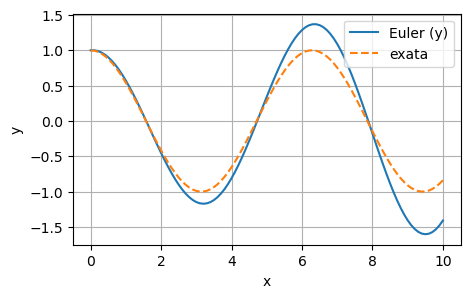

In [3]:
F = lambda x, Y: np.array([Y[1], -Y[0]])

h = 0.1
N = 100
x1, Y1 = euler_sistema(F, 0.0, np.array([1.0, 0.0]), h, N)

plt.plot(x1, Y1[:, 0], label='Euler (y)')
plt.plot(x1, np.cos(x1), '--', label='exata')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid()
plt.show()

O gráfico mostra a aproximação de Euler acompanhando a oscilação no início, mas se afastando progressivamente da solução exata, ou seja, a amplitude cresce artificialmente ao longo do tempo. Esse crescimento não é só o erro de truncamento habitual: para uma equação puramente oscilatória como essa, o método de Euler é **instável em tempos longos**, qualquer que seja $h$ (voltamos a esse ponto na Seção 8.2.1). Por isso, além de olhar o gráfico, também vale comparar o erro em um intervalo curto, onde o comportamento $O(h)$ esperado fica mais claro.

#### Atividade 8.1

Use `euler_sistema` para resolver o pêndulo linearizado $l\,\theta''=-g\theta$ com $g=9,8$, $l=1$, $\theta(0)=0,3$ rad e $\theta'(0)=0,5$ rad/s, no intervalo $[0,5]$ com $h=0,05$. Compare com a solução exata dada na Atividade 7.1, $\theta(t)=\theta_0\cos(\sqrt{g/l}\,t)+\omega_0\sqrt{l/g}\,sen(\sqrt{g/l}\,t)$.

**Exemplo 8.2:** vamos aplicar o método de Euler estendido à equação não-homogênea $y''-3y'-4y=3e^{2t}$ do Exemplo 7.7, agora com as condições iniciais $y(0)=1$, $y'(0)=0$, no intervalo $[0;\,0,5]$ com $h=0,05$.

Isolando $y''$, o sistema equivalente é $\mathbf{y}'=\mathbf{F}(t,\mathbf{y})$, com

$$\mathbf{F}(t,\mathbf{y})=\begin{bmatrix} y_2 \\ 3y_2+4y_1+3e^{2t} \end{bmatrix}, \qquad \mathbf{y}_0=\begin{bmatrix} 1\\ 0 \end{bmatrix}$$

Antes de comparar, obtemos a solução exata com `sympy`, como fizemos nos Exemplos 7.7–7.10 (agora resolvendo o PVI, não só a equação geral):

In [4]:
import sympy as sp

# variáveis
t = sp.symbols('t')
y = sp.Function('y')(t)

#derivadas
dy = y.diff(t)
d2y = y.diff(t,t)

# PVI
eq = d2y - 3*dy - 4*y - 3*sp.exp(2*t)
cond_ini = {y.subs(t, 0): 1, dy.subs(t, 0): 0}

#solução
sol = sp.dsolve(eq, y, ics=cond_ini)
sol

Eq(y(t), exp(4*t)/2 - exp(2*t)/2 + exp(-t))

In [5]:
y_ex = sp.lambdify(t, sol.rhs, 'numpy')

A solução exata é, portanto, $y(t) = e^{-t} + \frac{1}{2}e^{4t} - \frac{1}{2}e^{2t}$. Comparando com a aproximação de Euler:

In [6]:
F2 = lambda t, Y: np.array([Y[1], 3*Y[1] + 4*Y[0] + 3*np.exp(2*t)])

def tabela_erro(x, y_aprox, y_exata, nome="y_i"):
    """Imprime a tabela i, x_i, aproximação, valor exato e erro absoluto."""
    print(f"{'i':>3} {'x_i':>10} {nome:>14} {'y(x_i)':>12} {'Erro':>12}")
    print("-" * 56)
    for i in range(len(x)):
        erro = abs(y_exata[i] - y_aprox[i])
        print(f"{i:3d} {x[i]:10.4f} {y_aprox[i]:14.6f} {y_exata[i]:12.6f} {erro:12.4e}")

t2, Y2 = euler_sistema(F2, 0.0, np.array([1.0, 0.0]), 0.05, 10)
tabela_erro(t2, Y2[:, 0], y_ex(t2))

  i        x_i            y_i       y(x_i)         Erro
--------------------------------------------------------
  0     0.0000       1.000000     1.000000   0.0000e+00
  1     0.0500       1.000000     1.009345   9.3453e-03
  2     0.1000       1.017500     1.040048   2.2548e-02
  3     0.1500       1.055914     1.096838   4.0924e-02
  4     0.2000       1.119425     1.185589   6.6164e-02
  5     0.2500       1.213146     1.313581   1.0043e-01
  6     0.3000       1.343309     1.489817   1.4651e-01
  7     0.3500       1.517492     1.725412   2.0792e-01
  8     0.4000       1.744902     2.034066   2.8916e-01
  9     0.4500       2.036702     2.432650   3.9595e-01
 10     0.5000       2.406412     2.941918   5.3551e-01


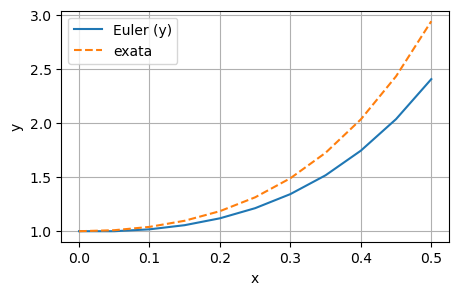

In [7]:
plt.plot(t2, Y2[:, 0], label='Euler (y)')
plt.plot(t2, y_ex(t2), '--', label='exata')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid()
plt.show()

O erro final (≈ 0,54, cerca de 18% do valor exato) é bem maior que o do Exemplo 8.1, mesmo num intervalo bem mais curto: a solução cresce rapidamente por causa do termo $e^{4t}$ do modo homogêneo, e o erro de Euler cresce junto. Isso motiva um método de ordem mais alta, o qual é assunto da Seção 8.3.

#### Atividade 8.2

Resolva com `euler_sistema` o PVI $y''-3y'-4y=2\,sen(t)$, $y(0)=1$, $y'(0)=0$ — a mesma equação do Exemplo 7.8 do Notebook 7 — no intervalo $[0;\,0,5]$ com $h=0,05$. Obtenha a solução exata com `sp.dsolve` (como no Exemplo 8.2) e compare.

#### 8.2.1 O erro do método de Euler estendido e o efeito do passo $h$

Como no caso escalar (Notebook 5, Seção 5.4), o método de Euler tem erro de truncamento local $O(h^2)$ a cada passo e erro global $O(h)$: ao dividir $h$ pela metade, o erro final deve cair, aproximadamente, pela metade também.

Para isolar esse comportamento sem a instabilidade de longo prazo observada no Exemplo 8.1, vamos medir o erro em $x=1$ (menos de meio período de oscilação) para a mesma equação $y''+y=0$.

        h     erro em x=1    razão
  0.20000        0.067698        -
  0.10000        0.030488     2.22
  0.05000        0.014378     2.12
  0.02500        0.006971     2.06
  0.01250        0.003431     2.03


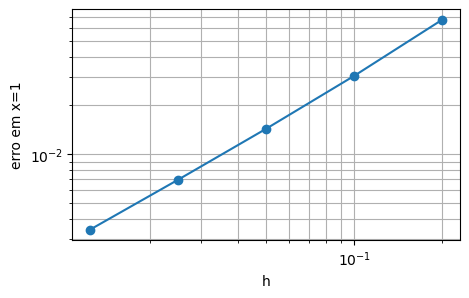

In [8]:
hs = np.array([0.2, 0.1, 0.05, 0.025, 0.0125])
erros = np.zeros(len(hs))

print(f"{'h':>9}{'erro em x=1':>16}{'razão':>9}")
for k, h in enumerate(hs):
    N = round(1.0 / h)
    x, Y = euler_sistema(F, 0.0, np.array([1.0, 0.0]), h, N)
    erros[k] = abs(Y[-1, 0] - np.cos(x[-1]))
    razao = "-" if k == 0 else f"{erros[k-1] / erros[k]:.2f}"
    print(f"{h:9.5f}{erros[k]:16.6f}{razao:>9}")

plt.loglog(hs, erros, 'o-')
plt.xlabel('h'); plt.ylabel('erro em x=1')
plt.grid(True, which='both')
plt.show()

A razão entre erros sucessivos fica próxima de 2, confirmando o erro global $O(h)$: cada vez que o passo é reduzido à metade, o erro final também cai, aproximadamente, à metade. No gráfico log-log os pontos se alinham a uma reta de inclinação 1.

### 8.3 Método de Taylor estendido

O método de Taylor de ordem 2 (Notebook 6) também se estende ao sistema. Como $y_1'=y_2$ exatamente, a expansão de $y_1$ já usa a própria EDO do sistema:

$$y_1(x_i+h) \approx y_1(x_i) + h\,y_2(x_i) + \frac{h^2}{2}f(x_i,y_1(x_i),y_2(x_i))$$

pois $y_1'=y_2$ e $y_1''=y_2'=f$. Já $y_2$ precisa de mais uma derivada: derivando $y_2'=f(x,y_1,y_2)$ pela regra da cadeia (como fizemos no Notebook 6 para o caso escalar) e substituindo $y_1'=y_2$, $y_2'=f$, obtemos

$$y_2'' = f_x + f_{y_1}\,y_2 + f_{y_2}\,f$$

$$y_2(x_i+h) \approx y_2(x_i) + h\,f(x_i,y_1(x_i),y_2(x_i)) + \frac{h^2}{2}y_2''(x_i)$$

Assim como fizemos no Notebook 6 (`taylor2_formula`), deixamos o `SymPy` derivar $y_2''$ automaticamente a partir de $f$, usando a mesma ideia: diferenciar totalmente em relação a $x$ e substituir as derivadas de $y_1$ e $y_2$ pelas próprias equações do sistema.

A função `taylor2_sistema_formula` a seguir deriva simbolicamente as fórmulas de recorrência do Taylor de ordem 2 para o sistema $y_1' = y_2$, $y_2' = f(x, y_1, y_2)$, em que `f_expr` é uma expressão SymPy em `x`, `y1` e `y2` (funções de $x$). Retorna (`prox_y1`, `prox_y2`, `d2y2`): as duas fórmulas de recorrência (em $x$, $y_1$, $y_2$ e no símbolo $h$, ainda não substituído) e a expressão de $y_2''$ (em $x$, $y_1$, $y_2$).

In [9]:
def taylor2_sistema_formula(f_expr, x, y1, y2):
    h = sp.Symbol('h')
    d2y2 = sp.diff(f_expr, x)
    d2y2 = d2y2.subs(sp.diff(y1, x), y2).subs(sp.diff(y2, x), f_expr)
    prox_y1 = y1 + y2*h + f_expr*h**2/2
    prox_y2 = y2 + f_expr*h + d2y2*h**2/2
    return prox_y1, prox_y2, d2y2

Vamos conferir para a equação do **Exemplo 8.1** em que $y''+y=0$, ou seja, $f(x,y_1,y_2)=-y_1$:

In [10]:
x_ = sp.Symbol('x')
y1_ = sp.Function('y1')(x_)
y2_ = sp.Function('y2')(x_)

prox_y1, prox_y2, d2y2_expr = taylor2_sistema_formula(-y1_, x_, y1_, y2_)

In [11]:
display(prox_y1)

-h**2*y1(x)/2 + h*y2(x) + y1(x)

In [12]:
display(prox_y2)

-h**2*y2(x)/2 - h*y1(x) + y2(x)

In [13]:
display(d2y2_expr)

-y2(x)

Ou seja, $y_2''=-y_2$: derivando $y_2'=-y_1$ e substituindo $y_1'=y_2$, obtemos exatamente o que já sabíamos de $y=\cos x$, já que $y'''=-y'$.


As fórmulas de recorrência ficam:

$$\mathbf{y}_{i+1}=\mathbf{y}_i+h\begin{bmatrix}y_{2,i}\\-y_{1,i}\end{bmatrix}+\frac{h^2}{2}\begin{bmatrix}-y_{1,i}\\-y_{2,i}\end{bmatrix}
\qquad \text{com} \qquad
\mathbf{y}_0=\begin{bmatrix}1\\0\end{bmatrix}$$

**Exemplo 8.3:** aplicando essas fórmulas — agora numericamente — ao mesmo PVI do Exemplo 8.1, com o mesmo passo $h=0,1$:

In [14]:
def taylor2_sistema(g, d2y2, x0, Y0, h, N):
    """Método de Taylor de ordem 2 para o sistema Y' = (y2, g(x, y1, y2)),
    usando a segunda derivada d2y2(x, Y) (tipicamente obtida com
    taylor2_sistema_formula + sp.lambdify, como abaixo).
    """
    x = np.zeros(N + 1)
    Y = np.zeros((N + 1, len(Y0)))
    x[0], Y[0] = x0, Y0
    for i in range(N):
        x[i + 1] = x[i] + h
        gi = g(x[i], Y[i])
        Y[i + 1, 0] = Y[i, 0] + h*Y[i, 1] + (h**2/2)*gi
        Y[i + 1, 1] = Y[i, 1] + h*gi + (h**2/2)*d2y2(x[i], Y[i])
    return x, Y

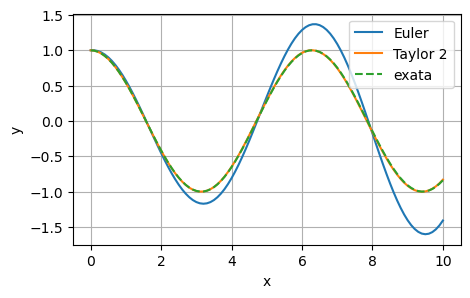

erro final Euler   : 0.5697754538395544
erro final Taylor 2: 0.00811710795153553


In [15]:
d2y2_1_raw = sp.lambdify((x_, y1_, y2_), d2y2_expr, 'numpy')
d2y2_1 = lambda x, Y: d2y2_1_raw(x, Y[0], Y[1])
g1 = lambda x, Y: -Y[0]   # y2' = g1(x, y1, y2) = -y1, a mesma f do Exemplo 8.1

h = 0.1
N = 100
xE, YE = euler_sistema(F, 0.0, np.array([1.0, 0.0]), h, N)
xT, YT = taylor2_sistema(g1, d2y2_1, 0.0, np.array([1.0, 0.0]), h, N)

plt.plot(xE, YE[:, 0], label='Euler')
plt.plot(xT, YT[:, 0], label='Taylor 2')
plt.plot(xE, np.cos(xE), '--', label='exata')
plt.xlabel('x'); plt.ylabel('y')
plt.legend(); plt.grid(); plt.show()

print('erro final Euler   :', abs(YE[-1, 0] - np.cos(xE[-1])))
print('erro final Taylor 2:', abs(YT[-1, 0] - np.cos(xT[-1])))

Com o mesmo passo, o erro final de Taylor 2 é cerca de 70 vezes menor que o de Euler — e o gráfico mostra a curva de Taylor 2 praticamente colada à exata, sem o crescimento visível de amplitude do Euler.

**Exemplo 8.4:** repetindo a comparação para a equação não-homogênea do Exemplo 8.2, derivando $y_2''$ automaticamente a partir de $f(t,y_1,y_2)=3y_2+4y_1+3e^{2t}$:

In [33]:
f_nb7 = 3*y2_ + 4*y1_ + 3*sp.exp(2*x_)
_, _, d2y2_2_expr = taylor2_sistema_formula(f_nb7, x_, y1_, y2_)
d2y2_2_expr

12*y1(x) + 13*y2(x) + 15*exp(2*x)

In [34]:
d2y2_2_raw = sp.lambdify((x_, y1_, y2_), d2y2_2_expr, 'numpy')
d2y2_2 = lambda t, Y: d2y2_2_raw(t, Y[0], Y[1])
g2 = lambda t, Y: 3*Y[1] + 4*Y[0] + 3*np.exp(2*t)   # y2' = g2(t, y1, y2), a mesma f do Exemplo 8.2
y_exata2 = lambda t: np.exp(4*t)/2 - np.exp(2*t)/2 + np.exp(-t)

h = 0.05
N = 10
tE, YE2 = euler_sistema(F2, 0.0, np.array([1.0, 0.0]), h, N)
tT, YT2 = taylor2_sistema(g2, d2y2_2, 0.0, np.array([1.0, 0.0]), h, N)

print('erro final Euler   :', abs(YE2[-1, 0] - y_exata2(tE[-1])))
print('erro final Taylor 2:', abs(YT2[-1, 0] - y_exata2(tT[-1])))

erro final Euler   : 0.5355061938000332
erro final Taylor 2: 0.0395641991341904


O erro cai de ≈ 0,54 (Euler) para ≈ 0,04 (Taylor 2) — uma melhora bem menor, em termos relativos, que a do Exemplo 8.3. Faz sentido: o termo $e^{4t}$ cresce rápido demais, no intervalo escolhido, para que um único passo maior de $h=0,05$ capture bem a curvatura; ainda assim, Taylor 2 é consistentemente melhor que Euler para o mesmo custo computacional.

#### 8.3.1 Comparando a ordem dos métodos

Vamos confirmar numericamente que o método de Euler estendido é $O(h)$ e o de Taylor de ordem 2 é $O(h^2)$, usando o mesmo PVI do Exemplo 8.1 e medindo o erro em $x=1$, como na Seção 8.2.1.

       h    erro Euler   razão    erro Taylor2   razão
  0.2000  6.769769e-02       -    5.018309e-03       -
  0.1000  3.048814e-02    2.22    1.331608e-03    3.77
  0.0500  1.437822e-02    2.12    3.419597e-04    3.89
  0.0250  6.971463e-03    2.06    8.658461e-05    3.95
  0.0125  3.431295e-03    2.03    2.178056e-05    3.98


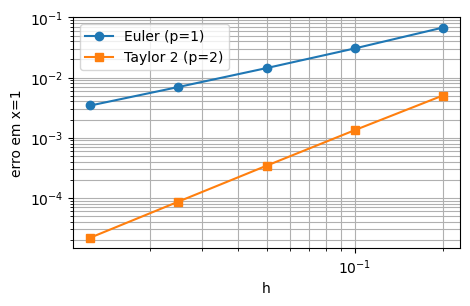

In [35]:
hs = np.array([0.2, 0.1, 0.05, 0.025, 0.0125])
erroE = np.zeros(len(hs))
erroT = np.zeros(len(hs))

for k, h in enumerate(hs):
    N = round(1.0 / h)
    xE, YE = euler_sistema(F, 0.0, np.array([1.0, 0.0]), h, N)
    xT, YT = taylor2_sistema(g1, d2y2_1, 0.0, np.array([1.0, 0.0]), h, N)
    erroE[k] = abs(YE[-1, 0] - np.cos(xE[-1]))
    erroT[k] = abs(YT[-1, 0] - np.cos(xT[-1]))

print(f"{'h':>8}{'erro Euler':>14}{'razão':>8}{'erro Taylor2':>16}{'razão':>8}")
for k in range(len(hs)):
    rE = "-" if k == 0 else f"{erroE[k-1]/erroE[k]:.2f}"
    rT = "-" if k == 0 else f"{erroT[k-1]/erroT[k]:.2f}"
    print(f"{hs[k]:8.4f}{erroE[k]:14.6e}{rE:>8}{erroT[k]:16.6e}{rT:>8}")

plt.loglog(hs, erroE, 'o-', label='Euler (p=1)')
plt.loglog(hs, erroT, 's-', label='Taylor 2 (p=2)')
plt.xlabel('h'); plt.ylabel('erro em x=1')
plt.legend(); plt.grid(True, which='both')
plt.show()

A razão entre erros sucessivos fica próxima de 2 para Euler e de 4 para Taylor 2, confirmando $O(h)$ e $O(h^2)$, respectivamente — no gráfico log-log os pontos se alinham a retas de inclinação 1 e 2.

#### Atividade 8.3

Repita a Atividade 8.1 (pêndulo linearizado, $\theta_0=0,3$, $\omega_0=0,5$) agora usando `taylor2_sistema`. Compare o erro final com o obtido pelo Euler estendido, para o mesmo $h=0,05$.

### 8.4 Solução numérica com SciPy

Como visto nos Notebooks 5 e 6, `scipy.integrate.solve_ivp` também resolve sistemas de EDOs diretamente — basta escrever a função do sistema retornando um vetor, exatamente como fizemos para `euler_sistema`. Não é preciso derivar fórmula nenhuma "na mão": a redução da Seção 8.1 é o único passo manual necessário.

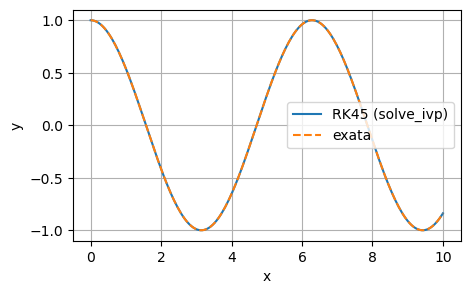

erro máximo RK45: 1.2090959566890547e-08


In [36]:
from scipy.integrate import solve_ivp

sol_ivp = solve_ivp(F, [0, 10], [1.0, 0.0], dense_output=True, rtol=1e-8, atol=1e-10)

xs = np.linspace(0, 10, 200)
Ys = sol_ivp.sol(xs)

plt.plot(xs, Ys[0], label='RK45 (solve_ivp)')
plt.plot(xs, np.cos(xs), '--', label='exata')
plt.xlabel('x'); plt.ylabel('y')
plt.legend(); plt.grid(); plt.show()

print('erro máximo RK45:', np.max(np.abs(Ys[0] - np.cos(xs))))

Diferente do Euler estendido, o `RK45` não mostra o crescimento artificial de amplitude visto no Exemplo 8.1 — o erro fica da ordem de $10^{-8}$, próximo da precisão de máquina, mesmo em 10 unidades de tempo (quase 2 períodos completos), graças ao passo adaptativo.

### 8.5 Exercícios

**1.** O pêndulo do Exemplo 7.1, sem a aproximação de ângulos pequenos, é a equação não-linear

$$l\,\theta''=-g\,sen(\theta), \qquad \theta(0)=0,5 \text{ rad}, \quad \theta'(0)=0$$

Use $g=9,8$ m/s² e $l=1$ m. Essa equação não tem solução analítica elementar (`sp.dsolve` não consegue resolvê-la). Resolva-a numericamente com `euler_sistema` e com `taylor2_sistema` (ou `solve_ivp`, como solução de referência) no intervalo $[0,10]$ e compare os gráficos com o do pêndulo linearizado ($sen\,\theta\approx\theta$, Exemplo 8.1 com $\theta_0=0,5$). A partir de que ponto as duas soluções passam a se afastar visivelmente?

**2.** ([Fonte](https://integrada.minhabiblioteca.com.br/reader/books/9788522123414/pageid/789)) O problema de contorno do Exercício 4 do Notebook 9,

$$y''=y'+2y+\cos x, \quad 0\le x\le\frac{\pi}{2}$$

tem solução $y(x)=-\frac{1}{10}(sen\,x+3\cos x)$. Como problema de valor **inicial**, as mesmas condições dão $y(0)=-0,3$ e $y'(0)=-0,1$. Resolva com `euler_sistema` e `taylor2_sistema` usando $h=0,1$ e $h=0,05$, e compare o erro final com a solução exata para os dois métodos e os dois passos.

**Referências**

ARENALES, Selma; DAREZZO, Artur. Cálculo Numérico: aprendizagem com Apoio de Software. Porto Alegre: Cengage Learning Brasil, 2016.

BURDEN, Richard L.; FAIRES, J D.; BURDEN, Annette M. Análise Numérica - Tradução da 10ª edição norte-americana. 3. ed. Porto Alegre: +A Educação - Cengage Learning Brasil, 2016.